##**Cargar los datos**
**1. Importar bibliotecas**

In [ ]:
import os
import json
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from google.colab import files
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Bibliotecas cargadas correctamente.")


Bibliotecas cargadas correctamente.


##**2. Subir el ZIP corregido**

In [ ]:
archivos = files.upload()

nombre_zip = next(
    n for n in archivos
    if n.lower().endswith(".zip")
)

carpeta = "/content/RentAI_entrenamiento"
os.makedirs(carpeta, exist_ok=True)

with zipfile.ZipFile(nombre_zip, "r") as zipf:
    zipf.extractall(carpeta)

print("Archivos encontrados:")

for raiz, _, nombres in os.walk(carpeta):
    for nombre in nombres:
        print(os.path.join(raiz, nombre))


Saving RentAI_preprocesamiento_corregido.zip to RentAI_preprocesamiento_corregido.zip
Archivos encontrados:
/content/RentAI_entrenamiento/y_test.csv
/content/RentAI_entrenamiento/X_test.csv
/content/RentAI_entrenamiento/X_test_procesado.npz
/content/RentAI_entrenamiento/y_train.csv
/content/RentAI_entrenamiento/X_train.csv
/content/RentAI_entrenamiento/resumen_limpieza.json
/content/RentAI_entrenamiento/preprocesador.joblib
/content/RentAI_entrenamiento/auditoria_variables.csv
/content/RentAI_entrenamiento/X_train_procesado.npz


##**3. Cargar las matrices y los precios**

In [ ]:
def buscar_archivo(nombre):
    for raiz, _, archivos in os.walk(carpeta):
        if nombre in archivos:
            return os.path.join(raiz, nombre)
    raise FileNotFoundError(nombre)

X_train = sparse.load_npz(
    buscar_archivo("X_train_procesado.npz")
)

X_test = sparse.load_npz(
    buscar_archivo("X_test_procesado.npz")
)

y_train = pd.read_csv(
    buscar_archivo("y_train.csv")
).iloc[:, 0].to_numpy(dtype=float)

y_test = pd.read_csv(
    buscar_archivo("y_test.csv")
).iloc[:, 0].to_numpy(dtype=float)

preprocesador = joblib.load(
    buscar_archivo("preprocesador.joblib")
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_test.shape[1]

print("Datos cargados correctamente.")


X_train: (12905, 115)
X_test: (3230, 115)
y_train: (12905,)
y_test: (3230,)
Datos cargados correctamente.


##**4.Entrenar los siete modelos**
**Crear las métricas de evaluación**

In [ ]:
resultados = []
modelos_entrenados = {}

def evaluar_modelo(nombre, modelo, X_prueba=X_test):
    predicciones = modelo.predict(X_prueba)

    mae = mean_absolute_error(
        y_test, predicciones
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predicciones)
    )

    r2 = r2_score(
        y_test, predicciones
    )

    # Error absoluto porcentual ponderado
    wape = (
        np.sum(np.abs(y_test - predicciones))
        / np.sum(np.abs(y_test))
    ) * 100

    resultados.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE_%": wape
    })

    print(
        f"{nombre}: "
        f"MAE=${mae:,.0f} | "
        f"RMSE=${rmse:,.0f} | "
        f"R²={r2:.4f} | "
        f"WAPE={wape:.2f}%"
    )

    return predicciones


##**5. Modelo base: mediana**

In [ ]:
modelo_base = DummyRegressor(
    strategy="median"
)

modelo_base.fit(X_train, y_train)

modelos_entrenados["Mediana"] = modelo_base

evaluar_modelo("Mediana", modelo_base)


Mediana: MAE=$47,570 | RMSE=$129,802 | R²=-0.0589 | WAPE=55.51%


array([55089., 55089., 55089., ..., 55089., 55089., 55089.], shape=(3230,))

##**6. Regresión lineal**

In [ ]:
modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train, y_train)

modelos_entrenados["Regresion lineal"] = modelo_lineal

evaluar_modelo(
    "Regresion lineal",
    modelo_lineal
)


Regresion lineal: MAE=$31,495 | RMSE=$78,485 | R²=0.6129 | WAPE=36.75%


array([69410.70881348, 77620.74175961, 39214.34226152, ...,
       86060.94402996, 36468.07308237, 40849.52871021], shape=(3230,))

##**7. Árbol de decisión**

In [ ]:
modelo_arbol = DecisionTreeRegressor(
    max_depth=18,
    min_samples_leaf=4,
    random_state=42
)

modelo_arbol.fit(X_train, y_train)

modelos_entrenados["Arbol de decision"] = modelo_arbol

evaluar_modelo(
    "Arbol de decision",
    modelo_arbol
)


Arbol de decision: MAE=$28,128 | RMSE=$82,086 | R²=0.5765 | WAPE=32.83%


array([76730.09090909, 52722.5       , 45996.19260417, ...,
       82952.405     , 44354.89649123, 48325.8516    ], shape=(3230,))

##**8. Random Forest**

In [ ]:
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

modelos_entrenados["Random Forest"] = modelo_rf

evaluar_modelo(
    "Random Forest",
    modelo_rf
)


Random Forest: MAE=$25,726 | RMSE=$73,016 | R²=0.6650 | WAPE=30.02%


array([78288.06333321, 59613.5726907 , 53498.6371647 , ...,
       79748.32881927, 45224.90622833, 51445.9556646 ], shape=(3230,))

##**9. Gradient Boosting**

In [ ]:
# Este algoritmo trabaja con matrices densas.
X_train_denso = X_train.toarray()
X_test_denso = X_test.toarray()

modelo_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

modelo_gb.fit(X_train_denso, y_train)

modelos_entrenados["Gradient Boosting"] = modelo_gb

evaluar_modelo(
    "Gradient Boosting",
    modelo_gb,
    X_test_denso
)


Gradient Boosting: MAE=$27,021 | RMSE=$75,046 | R²=0.6461 | WAPE=31.53%


array([61162.25281072, 76011.04062436, 48776.53786331, ...,
       75031.20315146, 52540.40046558, 60079.39759365], shape=(3230,))

##**10. Tres redes neuronales**

In [ ]:
arquitecturas = {
    "MLP 2 capas": (64, 32),
    "MLP 3 capas": (128, 64, 32),
    "MLP 4 capas": (128, 96, 64, 32)
}

historias_mlp = {}

for nombre, capas in arquitecturas.items():

    print("\nEntrenando:", nombre)

    modelo = MLPRegressor(
        hidden_layer_sizes=capas,
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=15,
        random_state=42
    )

    modelo.fit(X_train_denso, y_train)

    modelos_entrenados[nombre] = modelo
    historias_mlp[nombre] = modelo.loss_curve_

    evaluar_modelo(
        nombre,
        modelo,
        X_test_denso
    )



Entrenando: MLP 2 capas


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP 2 capas: MAE=$27,238 | RMSE=$75,745 | R²=0.6394 | WAPE=31.79%

Entrenando: MLP 3 capas
MLP 3 capas: MAE=$26,965 | RMSE=$73,253 | R²=0.6628 | WAPE=31.47%

Entrenando: MLP 4 capas
MLP 4 capas: MAE=$26,773 | RMSE=$74,777 | R²=0.6486 | WAPE=31.24%


##**3. Comparar los resultados**
**11. Tabla comparativa**

In [ ]:
tabla = pd.DataFrame(resultados)

tabla = tabla.sort_values(
    "MAE",
    ascending=True
).reset_index(drop=True)

display(tabla.round(4))

tabla.to_csv(
    "RentAI_comparacion_modelos.csv",
    index=False
)

mae_base = tabla.loc[
    tabla["Modelo"] == "Mediana", "MAE"
].iloc[0]

print("\nMejora frente a la mediana:")

for _, fila in tabla.iterrows():
    mejora = (
        (mae_base - fila["MAE"])
        / mae_base
    ) * 100

    print(
        fila["Modelo"],
        f"{mejora:.2f}%"
    )


,Modelo,MAE,RMSE,R2,WAPE_%
0,Random Forest,25725.9153,73015.6457,0.6650,30.0220
1,MLP 4 capas,26773.3927,74776.6122,0.6486,31.2444
2,MLP 3 capas,26964.7735,73253.3889,0.6628,31.4677
3,Gradient Boosting,27020.5337,75045.6275,0.6461,31.5328
4,MLP 2 capas,27237.9438,75745.3051,0.6394,31.7865
5,Arbol de decision,28128.2760,82086.1334,0.5765,32.8255
6,Regresion lineal,31495.0018,78484.8486,0.6129,36.7545
7,Mediana,47569.9145,129801.6784,-0.0589,55.5138



Mejora frente a la mediana:
Random Forest 45.92%
MLP 4 capas 43.72%
MLP 3 capas 43.32%
Gradient Boosting 43.20%
MLP 2 capas 42.74%
Arbol de decision 40.87%
Regresion lineal 33.79%
Mediana 0.00%


##**12. Gráfico de comparación**

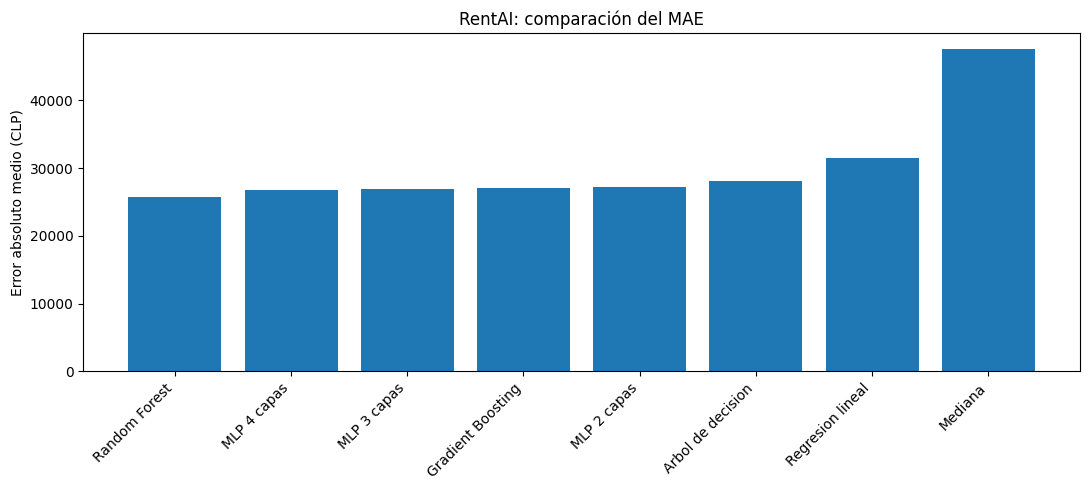

In [ ]:
plt.figure(figsize=(11, 5))

plt.bar(
    tabla["Modelo"],
    tabla["MAE"]
)

plt.title("RentAI: comparación del MAE")
plt.ylabel("Error absoluto medio (CLP)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "RentAI_comparacion_MAE.png",
    dpi=200
)

plt.show()


##**13. Curvas de convergencia de las redes**

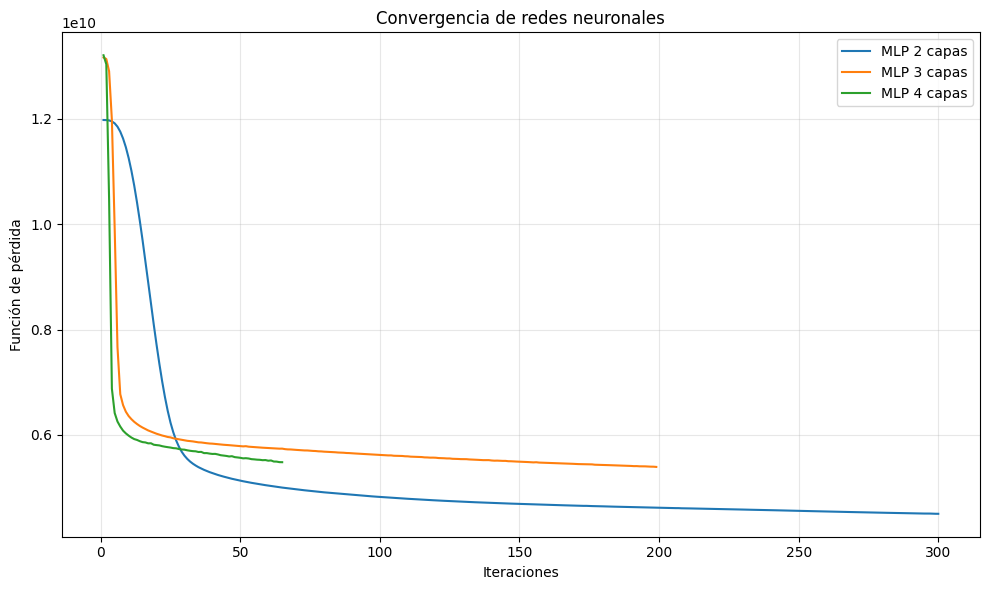

In [ ]:
plt.figure(figsize=(10, 6))

for nombre, perdidas in historias_mlp.items():
    plt.plot(
        range(1, len(perdidas) + 1),
        perdidas,
        label=nombre
    )

plt.title("Convergencia de redes neuronales")
plt.xlabel("Iteraciones")
plt.ylabel("Función de pérdida")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "RentAI_convergencia_MLP.png",
    dpi=200
)

plt.show()


##**4. Optimizar Random Forest**
**14. Buscar mejores hiperparámetros**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

parametros = {
    "n_estimators": [100, 150, 200],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [2, 4, 6]
}

busqueda = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=parametros,
    n_iter=8,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda.fit(X_train, y_train)

modelo_rf_optimizado = busqueda.best_estimator_

print("Mejores parámetros:")
print(busqueda.best_params_)

print("MAE promedio de validación cruzada:")
print(-busqueda.best_score_)

modelos_entrenados[
    "Random Forest optimizado"
] = modelo_rf_optimizado

evaluar_modelo(
    "Random Forest optimizado",
    modelo_rf_optimizado
)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores parámetros:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 6, 'max_depth': 20}
MAE promedio de validación cruzada:
25375.954924420916
Random Forest optimizado: MAE=$25,687 | RMSE=$72,952 | R²=0.6655 | WAPE=29.98%


array([78548.02843918, 60027.82984272, 48857.46946457, ...,
       79292.62228011, 45294.39890323, 53569.41919341], shape=(3230,))

##**15. Actualizar la comparación final**

In [16]:
tabla_final = pd.DataFrame(resultados)

tabla_final = tabla_final.sort_values(
    "MAE"
).reset_index(drop=True)

display(tabla_final.round(4))

tabla_final.to_csv(
    "RentAI_resultados_finales.csv",
    index=False
)

print(
    "Menor MAE:",
    tabla_final.iloc[0]["Modelo"]
)


,Modelo,MAE,RMSE,R2,WAPE_%
0,Random Forest optimizado,25687.2514,72952.4402,0.6655,29.9768
1,Random Forest,25725.9153,73015.6457,0.6650,30.0220
2,MLP 4 capas,26773.3927,74776.6122,0.6486,31.2444
3,MLP 3 capas,26964.7735,73253.3889,0.6628,31.4677
4,Gradient Boosting,27020.5337,75045.6275,0.6461,31.5328
5,MLP 2 capas,27237.9438,75745.3051,0.6394,31.7865
6,Arbol de decision,28128.2760,82086.1334,0.5765,32.8255
7,Regresion lineal,31495.0018,78484.8486,0.6129,36.7545
8,Mediana,47569.9145,129801.6784,-0.0589,55.5138


Menor MAE: Random Forest optimizado


##**Explicar predicciones con SHAP**
**16. Instalar SHAP**

In [17]:
!pip -q install shap

##**17. Explicar tres alojamientos**


Alojamiento 1
Precio real: 94800.0
Precio estimado: 78548.02843918468


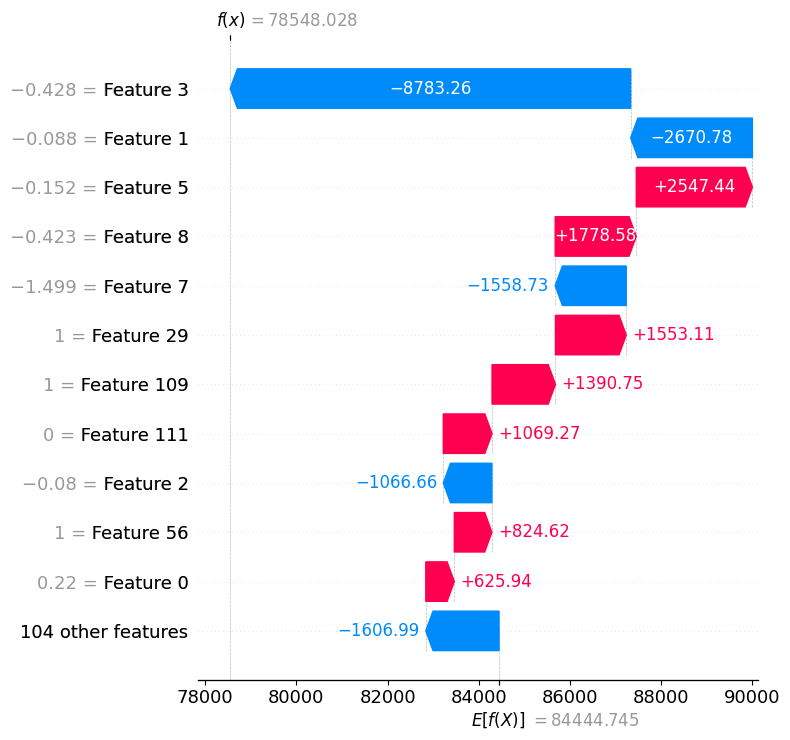


Alojamiento 2
Precio real: 50521.0
Precio estimado: 60027.82984271625


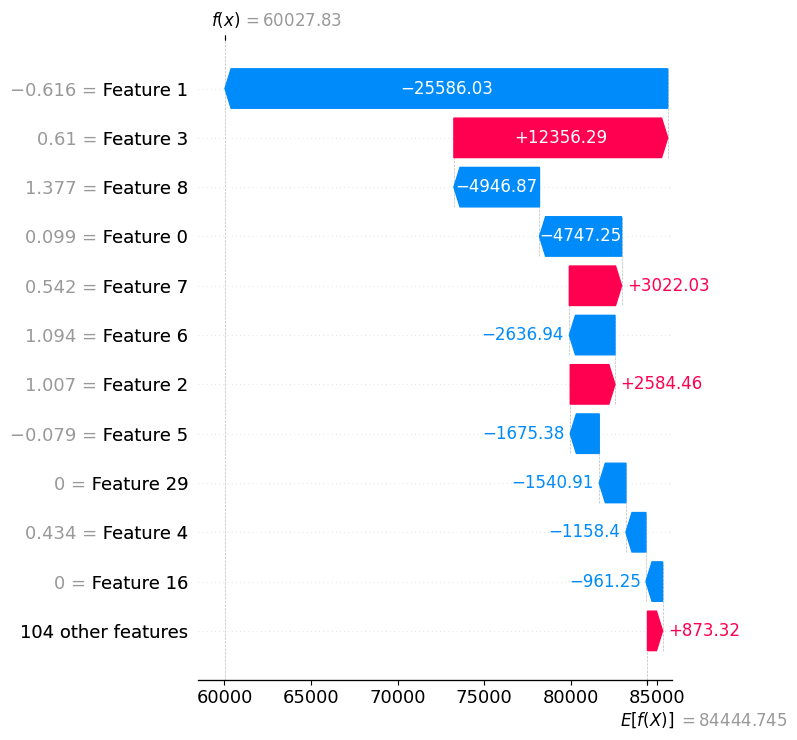


Alojamiento 3
Precio real: 45917.0
Precio estimado: 48857.46946456964


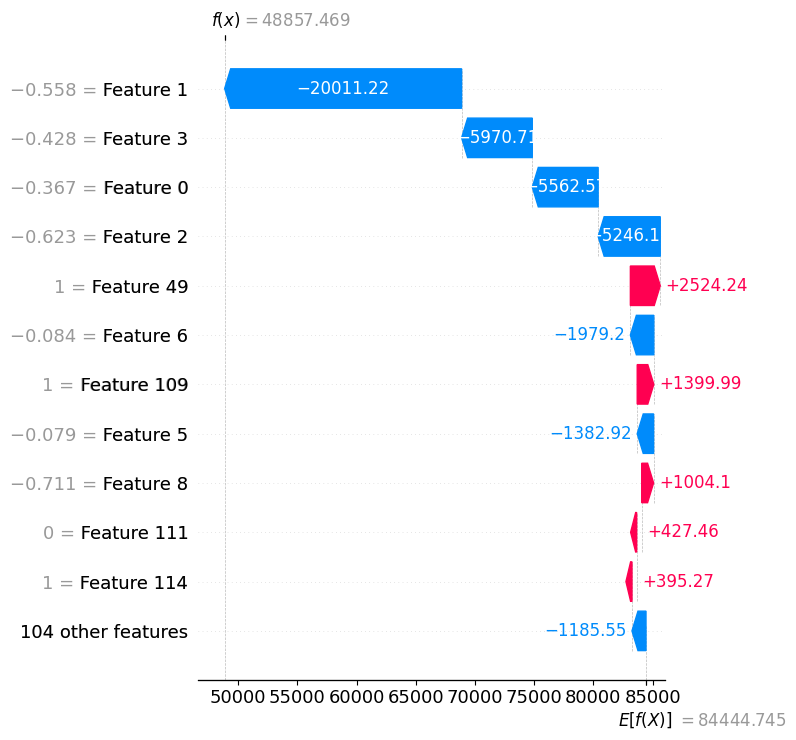

In [18]:
import shap

# Seleccionar tres alojamientos de prueba
X_ejemplos = X_test[:3].toarray()

# Nombres de las variables procesadas
nombres_variables = (
    preprocesador.get_feature_names_out()
)

# Explicar el Random Forest
explainer = shap.TreeExplainer(
    modelo_rf_optimizado
)

valores_shap = explainer(X_ejemplos)

for i in range(3):
    print(f"\nAlojamiento {i + 1}")
    print("Precio real:", y_test[i])
    print(
        "Precio estimado:",
        modelo_rf_optimizado.predict(
            X_test[i]
        )[0]
    )

    shap.plots.waterfall(
        valores_shap[i],
        max_display=12,
        show=False
    )

    plt.tight_layout()
    plt.savefig(
        f"RentAI_SHAP_caso_{i+1}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


##**Guardar los modelos**

In [19]:
os.makedirs(
    "RentAI_modelos_corregidos",
    exist_ok=True
)

nombres_archivos = {
    "Mediana": "modelo_mediana.joblib",
    "Regresion lineal": "modelo_lineal.joblib",
    "Arbol de decision": "modelo_arbol.joblib",
    "Random Forest": "modelo_random_forest.joblib",
    "Gradient Boosting": "modelo_gradient_boosting.joblib",
    "MLP 2 capas": "modelo_mlp_2.joblib",
    "MLP 3 capas": "modelo_mlp_3.joblib",
    "MLP 4 capas": "modelo_mlp_4.joblib",
    "Random Forest optimizado": "modelo_rf_optimizado.joblib"
}

for nombre, modelo in modelos_entrenados.items():
    ruta = os.path.join(
        "RentAI_modelos_corregidos",
        nombres_archivos[nombre]
    )

    joblib.dump(modelo, ruta)

joblib.dump(
    preprocesador,
    "RentAI_modelos_corregidos/preprocesador.joblib"
)

tabla_final.to_csv(
    "RentAI_modelos_corregidos/resultados.csv",
    index=False
)

print("Modelos guardados correctamente.")


Modelos guardados correctamente.


##**Descargar los resultados**

In [20]:
import zipfile

nombre_zip_salida = "RentAI_entrenamiento_corregido.zip"

archivos_extra = [
    "RentAI_comparacion_MAE.png",
    "RentAI_convergencia_MLP.png",
    "RentAI_resultados_finales.csv",
    "RentAI_SHAP_caso_1.png",
    "RentAI_SHAP_caso_2.png",
    "RentAI_SHAP_caso_3.png"
]

with zipfile.ZipFile(
    nombre_zip_salida,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for raiz, _, archivos in os.walk(
        "RentAI_modelos_corregidos"
    ):
        for archivo in archivos:
            ruta = os.path.join(raiz, archivo)
            zipf.write(ruta)

    for archivo in archivos_extra:
        if os.path.exists(archivo):
            zipf.write(archivo)

files.download(nombre_zip_salida)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
from pathlib import Path

print("=== BUSCANDO MODELOS ENTRENADOS ===")

for archivo in Path("/content").rglob("*.joblib"):
    print(archivo)

=== BUSCANDO MODELOS ENTRENADOS ===
/content/RentAI_modelos_corregidos/modelo_arbol.joblib
/content/RentAI_modelos_corregidos/modelo_random_forest.joblib
/content/RentAI_modelos_corregidos/modelo_mlp_4.joblib
/content/RentAI_modelos_corregidos/modelo_mlp_2.joblib
/content/RentAI_modelos_corregidos/modelo_gradient_boosting.joblib
/content/RentAI_modelos_corregidos/preprocesador.joblib
/content/RentAI_modelos_corregidos/modelo_rf_optimizado.joblib
/content/RentAI_modelos_corregidos/modelo_mlp_3.joblib
/content/RentAI_modelos_corregidos/modelo_lineal.joblib
/content/RentAI_modelos_corregidos/modelo_mediana.joblib
/content/RentAI_entrenamiento/preprocesador.joblib


In [23]:
from google.colab import files

# Descargar Random Forest optimizado
files.download(
    "/content/RentAI_modelos_corregidos/modelo_rf_optimizado.joblib"
)

# Descargar el preprocesador correspondiente
files.download(
    "/content/RentAI_modelos_corregidos/preprocesador.joblib"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>